<a href="https://colab.research.google.com/github/Vishali-Vivek006/Engineering-employability-prediction/blob/main/notebooks/07_employability_SHAP_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employability Core — Colab notebook
Resume → validated model row → probability → SHAP, using your **existing** saved preprocessor + model (nothing is refit).

**Files you need to upload:**
1. `skills_registry.py`  ← imported by the code (`SKILLS`, `MODEL_TECH_SKILL_KEYS`, `MODEL_PROFILE_FIELDS`, `SOFT_SKILL_COLUMNS`, `display_name`)
2. your saved model `.joblib` and fitted preprocessor `.joblib` (from the **same** training run)
3. *(optional)* the training dataset CSV (SHAP background + validation)
4. *(optional)* a resume `.pdf` / `.docx`

The module in step 3 is your code, unchanged.

## 1. Install dependencies

In [1]:
!pip -q install shap pypdf python-docx joblib
# Use the same scikit-learn version that created your .joblib files, e.g.
# !pip -q install scikit-learn==<version>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 19.2 MB/s eta 0:00:00


## 2. Upload your files

In [2]:
from google.colab import files
uploaded = files.upload()   # skills_registry.py, model .joblib, preprocessor .joblib, dataset .csv, resume
print(list(uploaded))

[]


## 3. `employability_core.py` (unchanged)

In [3]:
%%writefile employability_core.py
"""
employability_core.py
=====================
Resume -> validated model row -> probability -> SHAP, reusing the EXISTING saved
preprocessor + model. Nothing here fits the preprocessor or retrains the model.

Pipeline assumed (verified at run time by audit_artifacts, not hard-coded):
    raw row (153 cols) --preprocessor--> 169 features --model Pipeline(scaler, LogisticRegression)
"""
import io
import os
import re
import base64
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from skills_registry import (SKILLS, MODEL_TECH_SKILL_KEYS, MODEL_PROFILE_FIELDS,
                             SOFT_SKILL_COLUMNS, display_name)

TARGET_COL = "Placement_Status"
LEAKAGE_COLS = {"Student_ID", "Data_Source", "Placement_Status"}
PLACED_CANDIDATES = (1, "1", "Placed", "placed", True)

# Fields without which no prediction is shown (never silently imputed).
CRITICAL_FIELDS = ["Education_Level", "UG_Degree", "Branch", "Year", "CGPA",
                   "Backlogs", "Internship", "Project_Count"]


class ArtifactError(RuntimeError):
    """Missing / incompatible model artifacts."""


class ResumeError(RuntimeError):
    """Unreadable or unsupported resume."""


class InputValidationError(ValueError):
    """The student row cannot safely be sent to the model."""


# =============================================================================
# 1. ARTIFACTS + AUDIT
# =============================================================================
def load_artifacts(model_path, preprocessor_path):
    for label, p in (("trained model", model_path), ("fitted preprocessor", preprocessor_path)):
        if not os.path.exists(p):
            raise ArtifactError(
                f"Missing {label}: {p}\nRecovery: re-export it from the training notebook with "
                f"joblib.dump(<object>, '{os.path.basename(p)}') and upload it to the same folder. "
                f"The model and preprocessor MUST come from the same training run.")
    try:
        return joblib.load(model_path), joblib.load(preprocessor_path)
    except Exception as e:  # version mismatch, corrupt file, ...
        raise ArtifactError(f"Could not unpickle artifacts ({type(e).__name__}: {e}). "
                            "Use the same scikit-learn version that created them.") from e


def final_estimator(model):
    return model.steps[-1][1] if hasattr(model, "steps") else model


def pre_model_steps(model):
    """Steps of the model Pipeline that run before the final estimator (e.g. the scaler)."""
    if hasattr(model, "steps") and len(model.steps) > 1:
        from sklearn.pipeline import Pipeline
        return Pipeline(model.steps[:-1])
    return None


def resolve_placed_index(model):
    """Index of the 'Placed' class in model.classes_ (never assume column order)."""
    classes = list(getattr(model, "classes_", []))
    for i, c in enumerate(classes):
        if isinstance(c, (bool, np.bool_, int, np.integer)) and int(c) == 1:
            return i
        if isinstance(c, str) and c.strip().lower() in ("1", "placed"):
            return i
    raise ArtifactError(f"Cannot identify the 'Placed' class in model.classes_={classes}. "
                        "Expected 1 or 'Placed'.")


def _find_in_transformer(obj, attr):
    """Find first sub-estimator (searching Pipeline steps) that has fitted attribute `attr`."""
    if hasattr(obj, attr):
        return obj
    for _, step in getattr(obj, "steps", []):
        r = _find_in_transformer(step, attr)
        if r is not None:
            return r
    return None


def categorical_info(preprocessor):
    """{raw categorical column: [valid categories]} + handle_unknown flag, from the FITTED encoder."""
    cats, handle = {}, {}
    for name, trans, cols in preprocessor.transformers_:
        if name == "remainder" or trans in ("drop", "passthrough"):
            continue
        enc = _find_in_transformer(trans, "categories_")
        if enc is not None:
            for c, cat in zip(cols, enc.categories_):
                cats[c] = [str(x) for x in cat]
                handle[c] = getattr(enc, "handle_unknown", "error")
    return cats, handle


def imputer_fill_values(preprocessor):
    """{raw column: value the fitted imputer will substitute if the field is missing}."""
    fills = {}
    for name, trans, cols in preprocessor.transformers_:
        if name == "remainder" or trans in ("drop", "passthrough"):
            continue
        imp = _find_in_transformer(trans, "statistics_")
        if imp is not None:
            for c, v in zip(cols, imp.statistics_):
                fills[c] = v
    return fills


def clean_feature_names(preprocessor):
    try:
        names = list(preprocessor.get_feature_names_out())
    except Exception as e:
        raise ArtifactError(f"preprocessor.get_feature_names_out() failed: {e}")
    return [re.sub(r"^(num|cat|remainder)__", "", n) for n in names]


def column_groups(raw_columns):
    """Classify raw model columns. Unknown columns are returned, never ignored."""
    cols = set(raw_columns)
    g = {"tech_skills": [c for c in MODEL_TECH_SKILL_KEYS if c in cols]}
    for k, v in MODEL_PROFILE_FIELDS.items():
        g[k] = [c for c in v if c in cols]
    known = {c for v in g.values() for c in v}
    g["unclassified"] = [c for c in raw_columns if c not in known]
    return g


def audit_artifacts(model, preprocessor, alt_model=None, df=None):
    """Return a dict describing what was found and every integration problem detected."""
    issues, notes = [], []
    raw = list(getattr(preprocessor, "feature_names_in_", []))
    if not raw:
        issues.append("Preprocessor has no feature_names_in_ (fit it on a DataFrame).")
    out_names = clean_feature_names(preprocessor)
    n_in = getattr(model, "n_features_in_", None)
    if n_in is not None and n_in != len(out_names):
        issues.append(f"Model expects {n_in} features but preprocessor emits {len(out_names)}: "
                      "wrong model/preprocessor pair.")
    est = final_estimator(model)
    info = dict(model_type=type(model).__name__, final_estimator=type(est).__name__,
                pipeline_steps=[n for n, _ in getattr(model, "steps", [])],
                classes=list(getattr(model, "classes_", [])), n_raw=len(raw),
                n_processed=len(out_names), n_model_features=n_in,
                supports_predict_proba=hasattr(model, "predict_proba"))
    if not info["supports_predict_proba"]:
        issues.append("Model lacks predict_proba(): decision scores are NOT calibrated probabilities.")
    try:
        info["placed_index"] = resolve_placed_index(model)
    except ArtifactError as e:
        issues.append(str(e))
    cats, handle = categorical_info(preprocessor)
    info["categorical_columns"] = cats
    info["handle_unknown"] = handle
    info["groups"] = column_groups(raw)
    if info["groups"]["unclassified"]:
        issues.append("Model columns not recognised by the registry (will be asked, never zero-filled): "
                      f"{info['groups']['unclassified']}")
    miss_skill_cols = [c for c in MODEL_TECH_SKILL_KEYS if c not in raw]
    if miss_skill_cols:
        notes.append(f"Registry skills absent from model schema (ignored for prediction): {miss_skill_cols}")
    bad_cat = [c for c in cats if c not in raw]
    if bad_cat:
        issues.append(f"Categorical columns not in raw schema: {bad_cat}")
    leak = [c for c in raw if c in LEAKAGE_COLS]
    if leak:
        issues.append(f"Leakage columns used as model inputs: {leak}")
    notes.append("Role-context inputs exist in the model ("
                 f"{info['groups']['role_context'] + ['Relevant_Project_Count', 'Relevant_Certification_Count']}): "
                 "the employability score therefore depends on how the student answers these 4 questions.")
    # Compare two candidate model files
    if alt_model is not None:
        same = (type(alt_model).__name__ == type(model).__name__
                and getattr(alt_model, "n_features_in_", None) == n_in
                and list(getattr(alt_model, "classes_", [])) == info["classes"])
        diff = None
        try:
            a, b = final_estimator(model).coef_, final_estimator(alt_model).coef_
            diff = float(np.max(np.abs(a - b))) if a.shape == b.shape else "shape differs"
        except Exception:
            pass
        info["alt_model_comparison"] = dict(compatible=same, max_abs_coef_difference=diff)
        notes.append("Two model files were supplied. "
                     + ("They are numerically identical." if diff == 0.0 else
                        "They differ: choose explicitly (see alt_model_comparison); do not mix them."))
    if df is not None:
        info["dataset"] = audit_dataset(df, raw, cats)
        issues += info["dataset"]["issues"]
    return dict(info=info, issues=issues, notes=notes)


def audit_dataset(df, raw_columns, cats):
    issues = []
    missing = [c for c in raw_columns if c not in df.columns]
    if missing:
        issues.append(f"Dataset lacks model input columns: {missing[:10]}")
    if TARGET_COL not in df.columns:
        issues.append(f"Target column '{TARGET_COL}' not found.")
    rep = dict(n_rows=len(df), n_duplicate_rows=int(df.duplicated().sum()),
               target_distribution=(df[TARGET_COL].value_counts(normalize=True).round(3).to_dict()
                                    if TARGET_COL in df.columns else None),
               leakage_columns_present=[c for c in df.columns if c in LEAKAGE_COLS],
               missing_cells_pct=round(float(df[[c for c in raw_columns if c in df.columns]].isna().mean().mean()) * 100, 2))
    if "Data_Source" in df.columns:
        rep["data_source_values"] = df["Data_Source"].value_counts().to_dict()
    for c, valid in cats.items():
        if c in df.columns:
            unseen = set(df[c].dropna().astype(str)) - set(valid)
            if unseen:
                issues.append(f"{c}: dataset contains categories unknown to the fitted encoder: {sorted(unseen)[:5]}")
    rep["issues"] = issues
    return rep


def profile_dataset(df, raw_columns):
    """Per-column kind/range, used to build the input form from real data (not assumptions)."""
    prof = {}
    for c in raw_columns:
        if c not in df.columns:
            continue
        s = df[c].dropna()
        if s.dtype == object or str(s.dtype).startswith(("string", "category")):
            prof[c] = dict(kind="categorical", values=sorted(map(str, s.unique()))[:50])
        else:
            u = set(np.unique(s.to_numpy()))
            kind = "binary" if u <= {0, 1, 0.0, 1.0} else "continuous"
            prof[c] = dict(kind=kind, min=float(s.min()), max=float(s.max()),
                           missing_pct=round(float(df[c].isna().mean()) * 100, 2))
    return prof


# =============================================================================
# 2. RESUME TEXT + FIELD EXTRACTION
# =============================================================================
def _normalise_bullets(text):
    """PDF/Word bullets come out as \\x7f, private-use glyphs, etc. Map them all to '•'."""
    return re.sub(rf"[{_BULLET_GLYPHS}]", "•", text)


def extract_text(path):
    path = str(path)
    if not os.path.exists(path):
        raise ResumeError(f"File not found: {path}")
    ext = Path(path).suffix.lower()
    if ext == ".pdf":
        try:
            from pypdf import PdfReader
            reader = PdfReader(path)
            if reader.is_encrypted and not reader.decrypt(""):
                raise ResumeError("PDF is password-protected.")
            text = "\n".join((p.extract_text() or "") for p in reader.pages)
        except ResumeError:
            raise
        except Exception as e:
            raise ResumeError(f"Could not read PDF ({type(e).__name__}: {e}).") from e
        if len(text.strip()) < 30:
            raise ResumeError("No extractable text (likely a scanned/image PDF). OCR is required; "
                              "or paste the text / upload a DOCX instead.")
        return _normalise_bullets(text)
    if ext == ".docx":
        try:
            import docx
            d = docx.Document(path)
            parts = [p.text for p in d.paragraphs]
            for t in d.tables:
                for row in t.rows:
                    parts.append(" | ".join(c.text.strip() for c in row.cells))
            text = "\n".join(parts)
        except Exception as e:
            raise ResumeError(f"Could not read DOCX ({type(e).__name__}: {e}).") from e
        if len(text.strip()) < 30:
            raise ResumeError("DOCX contains no readable text.")
        return _normalise_bullets(text)
    raise ResumeError(f"Unsupported file type '{ext}'. Upload a .pdf or .docx resume.")


_HEADINGS = {
    "education": r"education(?:al)?(?: qualifications?| background)?|academic (?:background|qualifications?)",
    "skills": r"(?:technical |key )?skills(?: summary)?|technical proficienc(?:y|ies)|core competenc(?:y|ies)|tools(?: and technologies)?",
    "projects": r"(?:academic |personal |key )?projects?",
    "internships": r"internships?|work experience|professional experience|experience|training",
    "certifications": r"certifications?|certificates?|licen[cs]es?(?: and certifications?)?|courses",
    "achievements": r"achievements?|awards?|honou?rs|extra[- ]?curricular(?: activities)?|activities|positions? of responsibility|hackathons?",
    "other": r"summary|objective|profile|declaration|references|languages|interests|personal details",
}
_HEAD_RE = {k: re.compile(rf"^\W*(?:{v})\W*$", re.I) for k, v in _HEADINGS.items()}


def heading_of(line):
    s = line.strip()
    if 2 < len(s) <= 45:
        for k, rx in _HEAD_RE.items():
            if rx.match(s):
                return k
    return None


def segment_sections(text):
    sections, cur = {"header": []}, "header"
    for line in text.splitlines():
        h = heading_of(line)
        if h:
            cur = h
            sections.setdefault(cur, [])
        else:
            sections.setdefault(cur, []).append(line)
    return {k: "\n".join(v).strip() for k, v in sections.items()}


# ---- skill detection --------------------------------------------------------
def _alias_regex(alias, ambiguous):
    toks = [re.escape(t) for t in alias.split()]
    body = r"[\s\-]+".join(toks)
    return re.compile(rf"(?<![A-Za-z0-9+#]){body}(?![A-Za-z0-9+#])", 0 if ambiguous else re.I)


_PATTERNS = [(key, alias, _alias_regex(alias, s["ambiguous"]), s["ambiguous"])
             for key, s in SKILLS.items() for alias in s["aliases"]]


def detect_skills(text):
    """{skill_key: {'confidence': 'high'|'low', 'evidence': [matched strings]}}"""
    found = {}
    for key, alias, rx, amb in _PATTERNS:
        for m in rx.finditer(text):
            d = found.setdefault(key, dict(confidence="low" if amb else "high", evidence=[]))
            if not amb:
                d["confidence"] = "high"
            if m.group(0) not in d["evidence"] and len(d["evidence"]) < 3:
                d["evidence"].append(m.group(0))
    return found


# exact-alias mapping for the EXISTING extractor's technical_skills list
# (fixes the legacy bug where normalising "C++" -> "c" collided with "C")
_EXACT = {}
for _k, _s in SKILLS.items():
    for _a in [_s["display"]] + _s["aliases"] + [_k]:
        _EXACT.setdefault(_a.strip().lower(), _k)
_EXACT["c"] = "C"        # case handled by exact lowercase lookup, never by stripping punctuation
_EXACT["c++"] = "Cpp"


def map_skill_names(names):
    mapped, unmapped = {}, []
    for n in names:
        k = _EXACT.get(str(n).strip().lower())
        if k:
            mapped[k] = dict(confidence="high", evidence=[str(n)])
        else:
            unmapped.append(str(n))
    return mapped, unmapped


# ---- education / CGPA / counts ---------------------------------------------
_BRANCH_PATTERNS = [("CSE", r"(?i:computer science|computer engineering)|\bC\.?S\.?E\b"),
                    ("IT", r"(?i:information technology)|\bI\.?T\b"),
                    ("ECE", r"(?i:electronics (?:and|&) communication)|\bECE\b"),
                    ("EEE", r"(?i:electrical (?:and|&) electronics|electrical engineering)|\bEEE\b"),
                    ("Mechanical", r"(?i:mechanical)"), ("Civil", r"(?i:\bcivil\b)"),
                    ("Aerospace", r"(?i:aerospace|aeronautical)")]


def parse_education(text, education_mentions=()):
    blob = text + "\n" + " ".join(map(str, education_mentions))
    ug = re.search(r"\bB\.?\s?Tech\b|\bB\.\s?E\b\.?|\bBE\b|bachelor", blob, re.I)
    pg = re.search(r"\bM\.?\s?Tech\b|\bM\.\s?E\b|\bMCA\b|\bMBA\b|\bmaster", blob, re.I)
    level = None
    notes = []
    if ug and pg:
        notes.append("Both UG and PG degrees are mentioned: confirm the CURRENT level.")
    elif ug:
        level = "UG"
    elif pg:
        level = "PG"
    branches = [b for b, rx in _BRANCH_PATTERNS if re.search(rx, blob)]
    if len(branches) > 1:
        notes.append(f"Several branch keywords found {branches}: confirm your branch.")
    return dict(level_guess=level, branch_candidates=branches, notes=notes,
                degree_text=(ug or pg).group(0) if (ug or pg) else None)


def parse_cgpa(text, cgpa_mentions=()):
    blob = text + "\n" + "\n".join(map(str, cgpa_mentions))
    cands = []
    for m in re.finditer(r"(?:C\.?G\.?P\.?A|GPA)\s*[:\-–]?\s*(\d{1,2}(?:\.\d{1,3})?)(?:\s*/\s*(\d{1,2}(?:\.\d+)?))?", blob, re.I):
        cands.append((float(m.group(1)), float(m.group(2)) if m.group(2) else None))
    for m in re.finditer(r"(\d{1,2}(?:\.\d{1,3})?)\s*/\s*(10|4)\s*(?:C\.?G\.?P\.?A)?", blob, re.I):
        cands.append((float(m.group(1)), float(m.group(2))))
    uniq = []
    for c in cands:
        if c not in uniq:
            uniq.append(c)
    valid = [v for v, sc in uniq if (sc in (None, 10.0)) and 0 < v <= 10]
    other_scale = [(v, sc) for v, sc in uniq if sc not in (None, 10.0) or v > 10]
    return dict(candidates=uniq, best=valid[0] if len(set(valid)) == 1 else None,
                ambiguous=len(set(valid)) > 1,
                non_10_scale=other_scale)


_BULLET_GLYPHS = "\x7f\x95\uf000-\uf8ff●○■□➢➤❖▪◦·"
_BULLET = re.compile(rf"^\s*(?:[•\-\*–—{_BULLET_GLYPHS}])\s*")


def _is_bullet(line):
    return bool(_BULLET.match(line))


def _cut_at_other_heading(section_text, own):
    out = []
    for line in section_text.splitlines():
        h = heading_of(line)
        if h and h != own:
            break
        out.append(line)
    return "\n".join(out)


def estimate_project_count(section_text):
    """Title-line heuristic (a title: non-bullet, starts a block, followed by a bullet). Estimate only."""
    section = _cut_at_other_heading(section_text or "", "projects")
    lines = [l.strip() for l in section.splitlines() if l.strip()]
    n = 0
    for i, l in enumerate(lines):
        if _is_bullet(l) or len(l) > 110 or re.match(r"(?i)(technolog|tech stack|tools)", l):
            continue
        prev_ok = (i == 0) or lines[i - 1].rstrip().endswith((".", "!"))
        nxt_b = i + 1 < len(lines) and _is_bullet(lines[i + 1])
        if prev_ok and nxt_b and not l.endswith("."):
            n += 1
    return n


def estimate_certification_count(section_text):
    lines = [l for l in (section_text or "").splitlines() if l.strip()]
    bullets = [l for l in lines if _is_bullet(l)]
    return len(bullets) if bullets else len(lines)


def internship_signals(section_text):
    t = section_text or ""
    has_kw = bool(re.search(r"\bintern(?:ship)?\b|\btrainee\b", t, re.I))
    dur = re.search(r"(\d+(?:\.\d+)?)\s*(months?|weeks?)", t, re.I)
    months = None
    if dur:
        v = float(dur.group(1))
        months = round(v / 4.345, 1) if dur.group(2).lower().startswith("week") else v
    return dict(section_present=bool(t.strip()), internship_keyword=has_kw,
                duration_months_candidate=months,
                note=(None if has_kw or not t.strip() else
                      "The section labelled experience/internship contains NO 'intern' keyword and looks "
                      "like project work: not treated as an internship."))


def extract_resume(path=None, existing_json=None, text=None, filename=None):
    """
    Produce the extraction dict (same keys as the existing resume_extraction_output.json
    + extra evidence fields). Pass `existing_json` to reuse output from the project's own
    extractor; pass `path` (PDF/DOCX) to run the built-in fallback extractor.
    """
    notes = []
    if existing_json is not None:
        ex = dict(existing_json)
        text = text or "\n".join(str(ex.get(k, "")) for k in
                                 ("project_section", "internship_section", "certification_section"))
        mapped, unmapped = map_skill_names(ex.get("technical_skills", []))
        detections = mapped
        if unmapped:
            notes.append(f"Extractor skills outside the registry (kept, not scored): {unmapped}")
        sections = {"projects": ex.get("project_section", ""), "internships": ex.get("internship_section", ""),
                    "certifications": ex.get("certification_section", "")}
        fname = ex.get("resume_filename", filename or "existing_json")
        edu_m, cg_m = ex.get("education_mentions", []), ex.get("cgpa_mentions", [])
        notes.append("Skills come from your existing extraction JSON; no re-parsing of the PDF was done.")
    else:
        if text is None:
            text = extract_text(path)
        fname = filename or (os.path.basename(str(path)) if path else "pasted_text")
        sections = segment_sections(text)
        detections = detect_skills(text)
        edu_m, cg_m = [], []
        if not sections.get("projects"):
            notes.append("No 'Projects' heading found: project count must be entered manually.")
    full = text or ""
    edu = parse_education(full, edu_m)
    cgpa = parse_cgpa(full, cg_m)
    internship = internship_signals(sections.get("internships", ""))
    if internship["note"]:
        notes.append(internship["note"])
    if cgpa["non_10_scale"]:
        notes.append(f"CGPA found on a non-10 scale / >10: {cgpa['non_10_scale']} – not auto-converted.")
    by_cat = {}
    for k in detections:
        by_cat.setdefault(SKILLS[k]["domain"], []).append(display_name(k))
    return dict(
        resume_filename=fname,
        education_mentions=edu_m or ([edu["degree_text"]] if edu["degree_text"] else []),
        cgpa_mentions=cg_m or [f"CGPA {c[0]}" for c in cgpa["candidates"]],
        technical_skills=sorted(display_name(k) for k in detections),
        skills_by_category=by_cat,
        project_section=sections.get("projects", ""),
        internship_section=sections.get("internships", ""),
        certification_section=sections.get("certifications", ""),
        # --- extras produced by this module ---
        skill_detections=detections,
        education=edu, cgpa=cgpa, internship=internship,
        project_count_estimate=estimate_project_count(sections.get("projects", "")),
        certification_count_estimate=estimate_certification_count(sections.get("certifications", "")),
        hackathon_mention=bool(re.search(r"hackathon", full, re.I)),
        open_source_mention=bool(re.search(r"open[- ]source", full, re.I)),
        text_chars=len(full), parsing_notes=notes,
    )


# =============================================================================
# 3. PROFILE -> EXACT MODEL ROW
# =============================================================================
class StudentProfile:
    """
    Holds confirmed answers. Each field has a status:
      provided | confirmed_absent | not_applicable | unknown
    Each skill has a state: present | absent (confirmed) | unknown (not found / not confirmed).
    """

    def __init__(self):
        self.fields = {}        # col -> dict(value, status, source)
        self.skill_state = {}   # canonical key -> present|absent|unknown
        self.extra_present = set()

    def set(self, col, value, status="provided", source="user"):
        self.fields[col] = dict(value=value, status=status, source=source)

    def set_unknown(self, col):
        self.fields[col] = dict(value=None, status="unknown", source="not provided")

    def value(self, col):
        f = self.fields.get(col)
        return None if f is None or f["status"] == "unknown" else f["value"]

    def present_skills(self):
        return {k for k, v in self.skill_state.items() if v == "present"}


def apply_skill_review(profile, detections, confirmed_present, confirmed_absent=(), absent_domains=(), all_keys=None):
    """
    confirmed_present: keys the student ticked (parser-detected AND user-added).
    confirmed_absent : keys the student explicitly says they lack.
    absent_domains   : domains where the student confirms 'anything I did not tick, I do not have'.
    Everything else stays 'unknown' (NOT zero).
    """
    keys = all_keys or list(SKILLS)
    for k in keys:
        if k in confirmed_present:
            profile.skill_state[k] = "present"
        elif k in confirmed_absent or SKILLS[k]["domain"] in absent_domains:
            profile.skill_state[k] = "absent"
        else:
            profile.skill_state[k] = "unknown"
    return profile


def build_raw_row(profile, raw_columns, cat_info, handle_unknown):
    """
    Returns (DataFrame with EXACTLY raw_columns in order, report dict).
    - skills: present->1, absent->0, unknown->NaN (preprocessor imputer decides; flagged)
    - categorical: must map to a fitted category (case-insensitive) or error
    """
    row, errors, warnings_ = {}, [], []
    for c in raw_columns:
        if c in cat_info:
            v = profile.value(c)
            if v is None:
                row[c] = np.nan
                continue
            m = {x.lower().strip(): x for x in cat_info[c]}
            hit = m.get(str(v).lower().strip())
            if hit is None:
                msg = f"{c}='{v}' is not a category seen in training {cat_info[c]}."
                (warnings_ if handle_unknown.get(c) == "ignore" else errors).append(msg)
                row[c] = str(v)
            else:
                row[c] = hit
        elif c in SKILLS and c in MODEL_TECH_SKILL_KEYS:
            st = profile.skill_state.get(c, "unknown")
            row[c] = 1.0 if st == "present" else 0.0 if st == "absent" else np.nan
        else:
            v = profile.value(c)
            if v is None:
                row[c] = np.nan
            else:
                try:
                    row[c] = float(v)
                except (TypeError, ValueError):
                    errors.append(f"{c}='{v}' is not numeric.")
                    row[c] = np.nan
    df = pd.DataFrame([row], columns=list(raw_columns))
    missing_crit = [c for c in CRITICAL_FIELDS if c in raw_columns and pd.isna(df.iloc[0][c])]
    if df.iloc[0].get("Internship") == 1 and "Internship_Duration_Months" in raw_columns \
            and pd.isna(df.iloc[0]["Internship_Duration_Months"]):
        missing_crit.append("Internship_Duration_Months")
    errors += [f"Required field not provided: {c}" for c in missing_crit]
    # logical consistency
    g = lambda c: df.iloc[0][c] if c in df.columns else np.nan
    for rel, tot in (("Relevant_Project_Count", "Project_Count"),
                     ("Relevant_Certification_Count", "Certification_Count")):
        if pd.notna(g(rel)) and pd.notna(g(tot)) and g(rel) > g(tot):
            errors.append(f"{rel} ({g(rel)}) cannot exceed {tot} ({g(tot)}).")
    if pd.notna(g("CGPA")) and not 0 <= g("CGPA") <= 10:
        errors.append("CGPA must be on the 0-10 scale used by the model.")
    if pd.notna(g("Internship")) and g("Internship") == 0 and pd.notna(g("Internship_Duration_Months")) \
            and g("Internship_Duration_Months") > 0:
        errors.append("Internship=0 but duration>0.")
    return df, dict(errors=errors, warnings=warnings_)


def imputation_report(X_raw, preprocessor):
    """Fields the model will fill with training statistics (NOT student-provided)."""
    fills = imputer_fill_values(preprocessor)
    rows = []
    for c in X_raw.columns:
        if pd.isna(X_raw.iloc[0][c]):
            fv = fills.get(c, "n/a")
            rows.append(dict(field=c, imputed_with=fv,
                             kind=("skill" if c in MODEL_TECH_SKILL_KEYS else
                                   "soft skill" if c in SOFT_SKILL_COLUMNS else "profile")))
    return pd.DataFrame(rows, columns=["field", "imputed_with", "kind"])


# =============================================================================
# 4. PREDICTION
# =============================================================================
def transform_dense(preprocessor, X_raw):
    Xp = preprocessor.transform(X_raw)
    if hasattr(Xp, "toarray"):
        Xp = Xp.toarray()
    return np.asarray(Xp, dtype=float)


def predict_employability(model, preprocessor, X_raw):
    expected = list(preprocessor.feature_names_in_)
    if list(X_raw.columns) != expected:
        raise InputValidationError("Input columns differ from the fitted preprocessor "
                                   f"(missing={sorted(set(expected) - set(X_raw.columns))[:5]}, "
                                   f"extra={sorted(set(X_raw.columns) - set(expected))[:5]}).")
    Xp = transform_dense(preprocessor, X_raw)
    n_in = getattr(model, "n_features_in_", Xp.shape[1])
    if Xp.shape[1] != n_in:
        raise InputValidationError(f"Preprocessor produced {Xp.shape[1]} features; model expects {n_in}.")
    if not np.isfinite(Xp).all():
        raise InputValidationError("Non-finite values after preprocessing.")
    if not hasattr(model, "predict_proba"):
        raise ArtifactError("Model has no predict_proba(); refusing to present scores as probabilities.")
    proba = np.asarray(model.predict_proba(Xp))[0]
    classes = list(model.classes_)
    pi = resolve_placed_index(model)
    ni = [i for i in range(len(classes)) if i != pi]
    if len(classes) != 2:
        raise ArtifactError("This module handles binary Placed / Not Placed models only.")
    if not (np.isfinite(proba).all() and (proba >= 0).all() and (proba <= 1).all()
            and abs(proba.sum() - 1) < 1e-6):
        raise InputValidationError(f"Invalid probability vector {proba}.")
    pred = model.predict(Xp)[0]
    pred_by_argmax = classes[int(np.argmax(proba))]
    p_placed, p_not = float(proba[pi]), float(proba[ni[0]])
    return dict(
        predicted_label=pred, predicted_class="Placed" if pred == classes[pi] else "Not Placed",
        p_placed=p_placed, p_not_placed=p_not, classes=classes, placed_index=pi,
        decision_rule_consistent=bool(pred == pred_by_argmax),
        decision_rule="model.predict(); for binary Logistic Regression this equals P(Placed) >= 0.5",
        processed_shape=Xp.shape,
        interpretation=(f"The model assigns an estimated {p_placed:.1%} probability to the Placed class and "
                        f"{p_not:.1%} to Not Placed, so its predicted class is "
                        f"{'Placed' if pred == classes[pi] else 'Not Placed'}. This is a score learned from "
                        "SYNTHETIC training data; it is not a validated real-world placement probability "
                        "and not a guarantee of any outcome."))


# =============================================================================
# 5. SHAP
# =============================================================================
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def _background_matrix(model, preprocessor, background_df, n_background, seed=0):
    pre = pre_model_steps(model)
    if background_df is not None:
        raw = list(preprocessor.feature_names_in_)
        bg = background_df[raw]
        if len(bg) > n_background:
            bg = bg.sample(n_background, random_state=seed)
        Xp = transform_dense(preprocessor, bg)
        return pre.transform(Xp) if pre is not None else Xp, "dataset sample"
    from sklearn.preprocessing import StandardScaler
    scaler = pre.steps[-1][1] if pre is not None and len(pre.steps) == 1 else None
    if isinstance(scaler, StandardScaler) and scaler.with_mean:
        return np.zeros((2, len(scaler.mean_))), "training mean stored in the model's StandardScaler"
    return None, None


def explain_prediction(model, preprocessor, X_raw, background_df=None, n_background=300, top_n=8):
    import shap
    expected = list(preprocessor.feature_names_in_)
    if list(X_raw.columns) != expected:
        raise InputValidationError("Explaining a row whose columns differ from the prediction row.")
    names = clean_feature_names(preprocessor)
    Xp = transform_dense(preprocessor, X_raw)
    pre, est = pre_model_steps(model), final_estimator(model)
    Xm = pre.transform(Xp) if pre is not None else Xp
    pi = resolve_placed_index(model)
    bg, bg_desc = _background_matrix(model, preprocessor, background_df, n_background)
    kind = type(est).__name__

    if hasattr(est, "coef_") and kind in ("LogisticRegression", "SGDClassifier", "RidgeClassifier",
                                           "LinearSVC", "LogisticRegressionCV"):
        if bg is None:
            raise ArtifactError("Need background data (pass the dataset) to explain this linear model.")
        explainer = shap.LinearExplainer(est, shap.maskers.Independent(bg, max_samples=len(bg)))
        scale, explainer_name = "log-odds", "LinearExplainer (exact for linear models)"
        raw_vals = explainer.shap_values(Xm)
        raw_base = explainer.expected_value
        reference = est.decision_function(Xm)[0]
    elif kind in ("RandomForestClassifier", "ExtraTreesClassifier", "GradientBoostingClassifier",
                  "DecisionTreeClassifier", "XGBClassifier", "LGBMClassifier"):
        if bg is None:
            raise ArtifactError("Tree explanations need background data (pass the dataset).")
        explainer = shap.TreeExplainer(est, data=bg, feature_perturbation="interventional",
                                       model_output="probability")
        scale, explainer_name = "probability", "TreeExplainer (interventional, probability output)"
        raw_vals = explainer.shap_values(Xm, check_additivity=False)
        raw_base = explainer.expected_value
        reference = est.predict_proba(Xm)[0, pi]
    else:
        if bg is None:
            raise ArtifactError("Need background data (pass the dataset) for KernelExplainer.")
        f = lambda a: est.predict_proba(a)[:, pi]
        explainer = shap.KernelExplainer(f, shap.sample(bg, min(50, len(bg))))
        scale, explainer_name = "probability", "KernelExplainer (model-agnostic, approximate)"
        raw_vals = explainer.shap_values(Xm, nsamples=300)
        raw_base = explainer.expected_value
        reference = f(Xm)[0]

    # ---- normalise SHAP output formats to (n_features,) for the PLACED class -------
    if isinstance(raw_vals, list):                      # old API: list per class
        vals, base = np.asarray(raw_vals[pi])[0], np.atleast_1d(raw_base)[pi]
    else:
        arr = np.asarray(raw_vals)
        if arr.ndim == 3:                               # (n, features, classes)
            vals, base = arr[0, :, pi], np.atleast_1d(raw_base)[pi]
        else:                                           # (n, features) -> positive class = classes_[1]
            vals, base = arr[0], float(np.atleast_1d(raw_base)[0])
            if kind in ("LogisticRegression", "SGDClassifier", "RidgeClassifier", "LinearSVC",
                        "LogisticRegressionCV") and pi == 0:
                vals, base, reference = -vals, -base, -reference
    base = float(base)
    additivity_error = float(abs(base + vals.sum() - reference))
    tol = 1e-6 if scale == "log-odds" else 1e-2
    result = dict(
        explainer=explainer_name, background=bg_desc, scale=scale, base_value=base,
        output_value=base + float(vals.sum()), reference_output=float(reference),
        additivity_error=additivity_error, additivity_ok=bool(additivity_error <= tol),
        explained_class="Placed", feature_names=names, values=vals,
        base_probability=float(_sigmoid(base)) if scale == "log-odds" else base,
    )
    result["raw_table"] = aggregate_to_raw(vals, names, X_raw, preprocessor, imputation_report(X_raw, preprocessor))
    t = result["raw_table"]
    result["top_positive"] = t[t["shap"] > 0].head(top_n)
    result["top_negative"] = t[t["shap"] < 0].sort_values("shap").head(top_n)
    return result


def aggregate_to_raw(vals, processed_names, X_raw, preprocessor, imputed_df):
    """Sum one-hot columns back to their raw field so names/values are meaningful to a person."""
    cats, _ = categorical_info(preprocessor)
    raw_cols = list(X_raw.columns)
    imputed = set(imputed_df["field"]) if len(imputed_df) else set()
    owner = {}
    for n in processed_names:
        if n in raw_cols:
            owner[n] = n
        else:
            hit = [c for c in cats if n.startswith(c + "_")]
            owner[n] = max(hit, key=len) if hit else n
    agg = {}
    for n, v in zip(processed_names, vals):
        agg[owner[n]] = agg.get(owner[n], 0.0) + float(v)
    fills = imputer_fill_values(preprocessor)
    rows = []
    for c, v in agg.items():
        sv = X_raw.iloc[0][c] if c in X_raw.columns else np.nan
        was_imp = c in imputed
        shown = fills.get(c) if was_imp and pd.isna(sv) else sv
        rows.append(dict(feature=c, student_value=shown, shap=v, imputed=was_imp,
                         direction="toward Placed" if v > 0 else "away from Placed" if v < 0 else "neutral"))
    out = pd.DataFrame(rows)
    return out.reindex(out["shap"].abs().sort_values(ascending=False).index).reset_index(drop=True)


def _fmt(v):
    if isinstance(v, (float, np.floating)):
        return f"{v:g}" if not np.isnan(v) else "n/a"
    return str(v)


def explanation_text(pred, ex, top_n=5):
    unit = ("log-odds units (NOT percentage points)" if ex["scale"] == "log-odds"
            else "probability units")
    lines = [f"Model baseline (average training-like student): {ex['base_probability']:.1%} Placed. "
             f"This student's estimate is {pred['p_placed']:.1%}.",
             f"Contributions below are in {unit}; positive values push the model output toward Placed, "
             "negative values push it away. They describe the MODEL's behaviour, not causes of real placement."]

    def block(title, df):
        lines.append(title)
        if df.empty:
            lines.append("  (none)")
        for _, r in df.head(top_n).iterrows():
            tag = " [value NOT provided: model used typical training value]" if r["imputed"] else ""
            lines.append(f"  - {r['feature']} = {_fmt(r['student_value'])}: {r['shap']:+.3f}{tag}")
    block("Strongest factors pushing toward Placed:", ex["top_positive"])
    block("Strongest factors pushing away from Placed:", ex["top_negative"])
    n_imp = int(ex["raw_table"]["imputed"].sum())
    if n_imp:
        lines.append(f"Note: {n_imp} features were imputed rather than provided; treat their contributions as unverified.")
    return "\n".join(lines)


def _fig_to_b64(fig):
    import matplotlib.pyplot as plt
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=130, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def plot_shap_bar(ex, top_n=12):
    import matplotlib.pyplot as plt
    t = ex["raw_table"].head(top_n).iloc[::-1]
    colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in t["shap"]]
    labels = [f"{r.feature} = {_fmt(r.student_value)}" + ("*" if r.imputed else "") for r in t.itertuples()]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.3))
    ax.barh(labels, t["shap"], color=colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"SHAP value for class 'Placed' ({ex['scale']})")
    ax.set_title("Top feature contributions for this student (* = imputed, not provided)")
    return fig


def plot_shap_waterfall(ex, X_raw, max_display=12):
    """shap's own waterfall on the raw-feature level; falls back to cumulative bars."""
    import matplotlib.pyplot as plt
    import shap
    t = ex["raw_table"]
    try:
        exp = shap.Explanation(values=t["shap"].to_numpy(), base_values=ex["base_value"],
                               data=np.array([_fmt(v) for v in t["student_value"]], dtype=object),
                               feature_names=list(t["feature"]))
        shap.plots.waterfall(exp, max_display=max_display, show=False)
        fig = plt.gcf()
        fig.set_size_inches(8.5, 0.45 * max_display + 1.5)
        return fig
    except Exception:
        plt.close("all")
        top = t.head(max_display)
        fig, ax = plt.subplots(figsize=(8, 4))
        cum = ex["base_value"]
        for i, r in enumerate(top.itertuples()):
            ax.barh(i, r.shap, left=cum, color="#2a9d8f" if r.shap > 0 else "#e76f51")
            cum += r.shap
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(list(top["feature"]))
        ax.invert_yaxis()
        ax.axvline(ex["base_value"], ls="--", color="gray")
        ax.set_xlabel(f"cumulative output ({ex['scale']}) from baseline")
        return fig


# =============================================================================
# 6. VALIDATION OF THE MODEL ITSELF (discrimination + calibration)
# =============================================================================
def _metrics(y, p):
    from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, accuracy_score,
                                 confusion_matrix, brier_score_loss, log_loss)
    pred = (p >= 0.5).astype(int)
    bins = np.linspace(0, 1, 11)
    idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
    ece = sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(10) if (idx == b).any())
    return dict(roc_auc=roc_auc_score(y, p), accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), brier=brier_score_loss(y, p),
                log_loss=log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)), ece_10bin=float(ece),
                confusion_matrix=confusion_matrix(y, pred).tolist())


def evaluate_model(df, model, preprocessor, n_splits=5, seed=42):
    """
    (a) 'resubstitution': saved model on the full dataset - includes its own training rows, OPTIMISTIC.
        Its main use is catching a wrong model/preprocessor pair (AUC near 0.5).
    (b) 'cross_validated': CLONES of preprocessor+model scored out-of-fold (no leakage). The saved
        artifacts are untouched and nothing here calibrates or fits anything for a single student.
    """
    from sklearn.base import clone
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.calibration import calibration_curve
    import matplotlib.pyplot as plt
    raw = list(preprocessor.feature_names_in_)
    placed = model.classes_[resolve_placed_index(model)]
    X, y = df[raw], (df[TARGET_COL] == placed).astype(int).to_numpy()
    p_saved = model.predict_proba(transform_dense(preprocessor, X))[:, resolve_placed_index(model)]
    pipe = Pipeline([("pre", clone(preprocessor)), ("model", clone(model))])
    oof = cross_val_predict(pipe, X, y, cv=StratifiedKFold(n_splits, shuffle=True, random_state=seed),
                            method="predict_proba")[:, 1]
    res = dict(resubstitution=_metrics(y, p_saved), cross_validated=_metrics(y, oof), n=len(y),
               positive_rate=float(y.mean()))
    res["pair_check"] = ("OK" if res["resubstitution"]["roc_auc"] > 0.6 else
                         "SUSPICIOUS: saved model/preprocessor barely separate classes on this dataset - "
                         "likely a mismatched pair or target encoding.")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for pp, lab, col in ((oof, "cross-validated (clones)", "C0"), (p_saved, "saved model, full data (optimistic)", "C1")):
        fr, mp = calibration_curve(y, pp, n_bins=10, strategy="quantile")
        ax[0].plot(mp, fr, "o-", label=lab, color=col)
    ax[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax[0].set_xlabel("mean predicted P(Placed)"); ax[0].set_ylabel("observed fraction placed")
    ax[0].set_title("Reliability diagram"); ax[0].legend(fontsize=7)
    ax[1].hist(oof, bins=20, color="C0"); ax[1].set_title("Out-of-fold P(Placed) distribution")
    res["figure"] = fig
    c = res["cross_validated"]
    res["calibration_status"] = (f"Assessed on SYNTHETIC data by {n_splits}-fold CV of clones: Brier={c['brier']:.3f}, "
                                 f"log loss={c['log_loss']:.3f}, ECE(10 bins)={c['ece_10bin']:.3f}, ROC-AUC={c['roc_auc']:.3f}. "
                                 "Good synthetic-data calibration says nothing about real-world calibration.")
    return res


Writing employability_core.py


## 4. Load artifacts and audit them

In [5]:
import pandas as pd, pprint
import employability_core as ec

MODEL_PATH   = "employability_model.joblib"          # <- edit to your uploaded file names
PREPROC_PATH = "preprocessor.joblib"
DATA_PATH    = "Employability_dataset.csv"           # set to None if you have no dataset

model, pre = ec.load_artifacts(MODEL_PATH, PREPROC_PATH)
df = pd.read_csv(DATA_PATH) if DATA_PATH else None

audit = ec.audit_artifacts(model, pre, df=df)
pprint.pprint(audit["info"], width=110, compact=True)
print("\nISSUES:", *audit["issues"], sep="\n - ")
print("\nNOTES:", *audit["notes"], sep="\n - ")

{'categorical_columns': {'Branch': ['CSE', 'Civil', 'ECE', 'EEE', 'IT', 'Mechanical'],
                         'Education_Level': ['PG', 'UG'],
                         'PG_Specialization': ['M.E.', 'M.Sc', 'M.Tech', 'MBA', 'MCA', 'Unknown'],
                         'UG_Degree': ['B.Tech CSE', 'B.Tech Civil', 'B.Tech ECE', 'B.Tech EEE', 'B.Tech IT',
                                       'B.Tech Mechanical']},
 'classes': [np.int64(0), np.int64(1)],
 'dataset': {'data_source_values': {'Synthetic': 5000},
             'issues': [],
             'leakage_columns_present': ['Student_ID', 'Data_Source', 'Placement_Status'],
             'missing_cells_pct': 0.54,
             'n_duplicate_rows': 0,
             'n_rows': 5000,
             'target_distribution': {0: 0.574, 1: 0.426}},
 'final_estimator': 'LogisticRegression',
 'groups': {'academic': ['Year', 'CGPA', 'Attendance_Percentage', 'Backlogs', 'Core_Subject_Score',
                         'Technical_Subject_Score', 'Aptitude_Sc

## 5. Extract fields from a resume

In [6]:
RESUME_PATH = "resume.pdf"   # .pdf or .docx
ex = ec.extract_resume(path=RESUME_PATH)
print("Detected skills:", ex["technical_skills"])
print("CGPA:", ex["cgpa"])
print("Education:", ex["education"])
print("Project count (estimate):", ex["project_count_estimate"])
print("Certification count (estimate):", ex["certification_count_estimate"])
print("Internship signals:", ex["internship"])
print("Notes:", *ex["parsing_notes"], sep="\n - ")

Detected skills: ['C', 'C++', 'CSS', 'Computer Networks', 'Data Structures & Algorithms', 'Deep Learning', 'GitHub', 'HTML', 'Java', 'Machine Learning', 'MongoDB', 'MySQL', 'Node.js', 'Object-Oriented Programming', 'Operating Systems', 'Python', 'REST APIs', 'React', 'SQL', 'Web Development']
CGPA: {'candidates': [(8.55, None)], 'best': 8.55, 'ambiguous': False, 'non_10_scale': []}
Education: {'level_guess': None, 'branch_candidates': [], 'notes': [], 'degree_text': None}
Project count (estimate): 5
Certification count (estimate): 0
Internship signals: {'section_present': False, 'internship_keyword': False, 'duration_months_candidate': None, 'note': None}
Notes:


## 6. Confirm answers and build the model row
Edit every value yourself; missing critical fields are never guessed. Categorical values must match the categories printed in step 4 (`audit['info']['categorical_columns']`).

In [7]:
raw_cols = list(pre.feature_names_in_)
cats, handle = ec.categorical_info(pre)

p = ec.StudentProfile()
# --- EDIT THESE (use values valid for your model) ---
p.set("Education_Level", "UG")
p.set("UG_Degree", "B.Tech")
p.set("Branch", "IT")
p.set("Year", 3)
p.set("CGPA", ex["cgpa"]["best"] or 8.0)
p.set("Backlogs", 0)
p.set("Internship", 0)
p.set("Project_Count", ex["project_count_estimate"])
# p.set("Internship_Duration_Months", 2)   # required if Internship == 1
# p.set("Certification_Count", ex["certification_count_estimate"])
# p.set("Relevant_Project_Count", 1); p.set("Relevant_Certification_Count", 0)

# Skills: detected ones are marked present; anything not confirmed stays 'unknown'
confirmed_present = set(ex["skill_detections"])
ec.apply_skill_review(p, ex["skill_detections"], confirmed_present, absent_domains=())

X_raw, rep = ec.build_raw_row(p, raw_cols, cats, handle)
print("Errors:", *rep["errors"], sep="\n - ")
print("Warnings:", *rep["warnings"], sep="\n - ")
display(ec.imputation_report(X_raw, pre))

Errors:
Warnings:
 - UG_Degree='B.Tech' is not a category seen in training ['B.Tech CSE', 'B.Tech Civil', 'B.Tech ECE', 'B.Tech EEE', 'B.Tech IT', 'B.Tech Mechanical'].


,field,imputed_with,kind
0,PG_Specialization,Unknown,profile
1,PG_Required_For_Target_Role,0.0,profile
2,Relevant_Degree_Required,1.0,profile
3,Attendance_Percentage,82.1,profile
4,Core_Subject_Score,66.2,profile
...,...,...,...
120,Teamwork,60.0,soft skill
121,Leadership,53.5,soft skill
122,Problem_Solving,60.5,soft skill
123,Presentation,54.8,soft skill


## 7. Predict

In [8]:
assert not rep["errors"], "Fix the errors above before predicting."
pred = ec.predict_employability(model, pre, X_raw)
print(pred["predicted_class"], f"| P(Placed) = {pred['p_placed']:.1%}")
print(pred["interpretation"])

Placed | P(Placed) = 71.6%
The model assigns an estimated 71.6% probability to the Placed class and 28.4% to Not Placed, so its predicted class is Placed. This is a score learned from SYNTHETIC training data; it is not a validated real-world placement probability and not a guarantee of any outcome.


## 8. Explain with SHAP

Additivity OK: True | explainer: LinearExplainer (exact for linear models)
Model baseline (average training-like student): 47.1% Placed. This student's estimate is 71.6%.
Contributions below are in log-odds units (NOT percentage points); positive values push the model output toward Placed, negative values push it away. They describe the MODEL's behaviour, not causes of real placement.
Strongest factors pushing toward Placed:
  - Project_Count = 5: +0.560
  - CGPA = 8.55: +0.322
  - Computer_Networks = 1: +0.250
  - C = 1: +0.180
  - Operating_Systems = 1: +0.134
Strongest factors pushing away from Placed:
  - Internship = 0: -0.363
  - REST_API = 1: -0.197
  - Deep_Learning = 1: -0.173
  - Web_Development = 1: -0.106
  - Year = 3: -0.083
Note: 125 features were imputed rather than provided; treat their contributions as unverified.


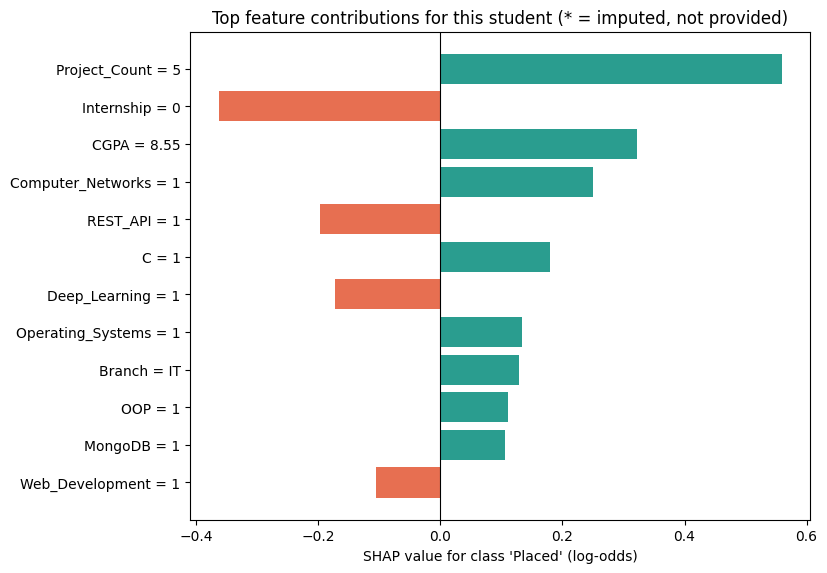

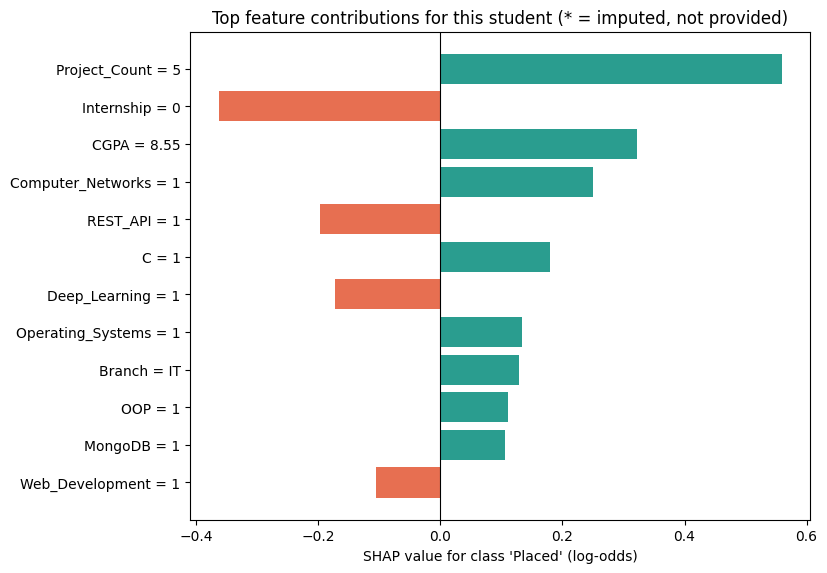

In [9]:
sx = ec.explain_prediction(model, pre, X_raw, background_df=df)
print("Additivity OK:", sx["additivity_ok"], "| explainer:", sx["explainer"])
print(ec.explanation_text(pred, sx))
ec.plot_shap_bar(sx)

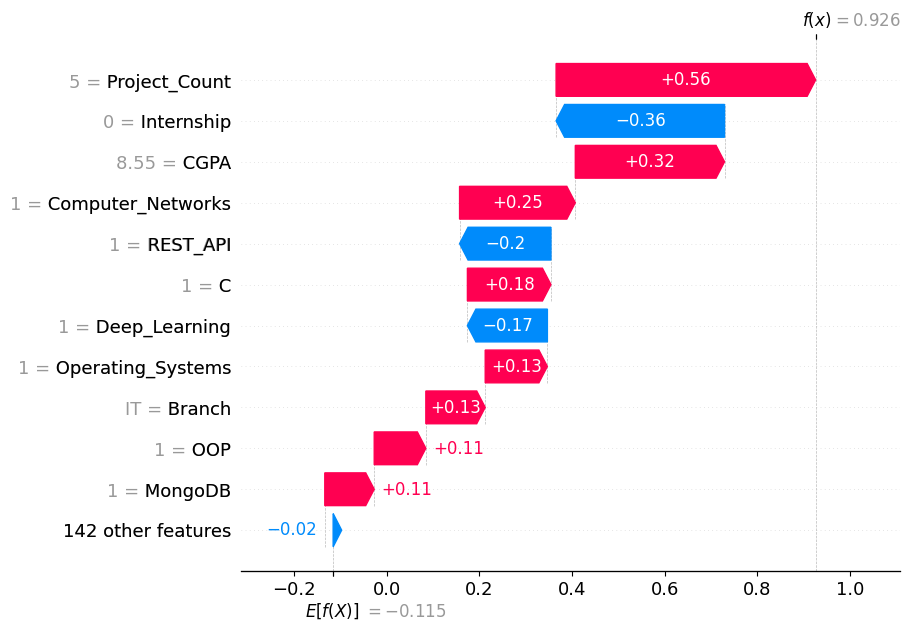

In [10]:
ec.plot_shap_waterfall(sx, X_raw)

## 9. (Optional) Validate the model on your dataset
Uses cross-validated *clones*; your saved artifacts are not modified.

In [11]:
if df is not None:
    res = ec.evaluate_model(df, model, pre)
    print(res["pair_check"]); print(res["calibration_status"])
    pprint.pprint(res["cross_validated"])
    res["figure"]

OK
Assessed on SYNTHETIC data by 5-fold CV of clones: Brier=0.210, log loss=0.610, ECE(10 bins)=0.059, ROC-AUC=0.734. Good synthetic-data calibration says nothing about real-world calibration.
{'accuracy': 0.6764,
 'brier': np.float64(0.20980682383968347),
 'confusion_matrix': [[1973, 899], [719, 1409]],
 'ece_10bin': 0.05941713924133834,
 'f1': 0.6352569882777277,
 'log_loss': 0.6102619835754165,
 'precision': 0.6104852686308492,
 'recall': 0.662124060150376,
 'roc_auc': np.float64(0.7342931885772928)}
